# The Office: OLS, Ridge, and Lasso

This notebook uses *The Office* transcripts together with the TidyTuesday IMDb ratings data.

We model

$
Y_i=\text{IMDb rating of episode }i
$

using three kinds of episode-level predictors:

1. **character dialogue:** number of lines spoken by recurring characters;
2. **creator indicators:** recurring writers and directors;
3. **season indicators.**

We compare

\[
\boxed{\text{OLS} \;\longrightarrow\; \text{Ridge} \;\longrightarrow\; \text{Lasso}.}
\]

The goal is to illustrate **regularization and sparsity**, not to make causal claims.  
A positive or negative coefficient means an association conditional on the other included predictors.


## 1. Setup

All user-adjustable thresholds are defined here so later cells can be run in order without hidden variables.


In [1]:
import sys
import subprocess
import importlib.util

# Install schrutepy into the CURRENT Jupyter kernel only if it is missing.
if importlib.util.find_spec("schrutepy") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "schrutepy"])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from schrutepy import schrutepy

from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score

RANDOM_STATE = 42

# -------------------------
# Teaching knobs
# -------------------------
MIN_CHARACTER_LINES = 50      # total dialogue lines across the series
MIN_CHARACTER_EPISODES = 5    # character must appear in at least this many episodes
MIN_CREATOR_EPISODES = 3      # writer/director must appear in at least this many episodes
TEST_SIZE = 0.25
N_FOLDS = 10

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 150)


## 2. Load the two data sources

The transcript table and the IMDb ratings are separate datasets.

- `schrutepy` supplies the transcript metadata and dialogue.
- TidyTuesday supplies `imdb_rating`, `total_votes`, and `air_date`.

The original analysis joins them using a normalized episode title because episode numbering is not perfectly aligned between the two sources.


In [2]:
# Transcript data: one row per spoken line
lines = schrutepy.load_schrute().copy()

# IMDb ratings: one row per episode
RATINGS_URL = (
    "https://raw.githubusercontent.com/"
    "rfordatascience/tidytuesday/main/data/2020/2020-03-17/"
    "office_ratings.csv"
)
ratings = pd.read_csv(RATINGS_URL)

print("Transcript columns:")
print(lines.columns.tolist())
print("\nRatings columns:")
print(ratings.columns.tolist())

display(lines.head())
display(ratings.head())


Transcript columns:
['index', 'season', 'episode', 'episode_name', 'director', 'writer', 'character', 'text', 'text_w_direction']

Ratings columns:
['season', 'episode', 'title', 'imdb_rating', 'total_votes', 'air_date']


,index,season,episode,episode_name,director,writer,character,text,text_w_direction
0,1,1,1,Pilot,Ken Kwapis,Ricky Gervais;Stephen Merchant;Greg Daniels,Michael,All right Jim. Your quarterlies look very good...,All right Jim. Your quarterlies look very good...
1,2,1,1,Pilot,Ken Kwapis,Ricky Gervais;Stephen Merchant;Greg Daniels,Jim,"Oh, I told you. I couldn't close it. So...","Oh, I told you. I couldn't close it. So..."
2,3,1,1,Pilot,Ken Kwapis,Ricky Gervais;Stephen Merchant;Greg Daniels,Michael,So you've come to the master for guidance? Is ...,So you've come to the master for guidance? Is ...
3,4,1,1,Pilot,Ken Kwapis,Ricky Gervais;Stephen Merchant;Greg Daniels,Jim,"Actually, you called me in here, but yeah.","Actually, you called me in here, but yeah."
4,5,1,1,Pilot,Ken Kwapis,Ricky Gervais;Stephen Merchant;Greg Daniels,Michael,"All right. Well, let me show you how it's done.","All right. Well, let me show you how it's done."


,season,episode,title,imdb_rating,total_votes,air_date
0,1,1,Pilot,7.6,3706,2005-03-24
1,1,2,Diversity Day,8.3,3566,2005-03-29
2,1,3,Health Care,7.9,2983,2005-04-05
3,1,4,The Alliance,8.1,2886,2005-04-12
4,1,5,Basketball,8.4,3179,2005-04-19


## 3. Normalize episode titles

Following the original analysis, remove punctuation and `"Part ..."` suffixes and convert titles to lower case.

For example, titles such as `"Niagara: Part 1"` and `"Niagara (Part 1)"` should map to the same normalized episode name.


In [3]:
def normalize_transcript_title(s):
    s = pd.Series(s, dtype="string")
    return (
        s.str.lower()
         .str.replace(r"\.", "", regex=True)
         .str.replace(r" \(part.*$", "", regex=True)
         .str.strip()
    )

def normalize_rating_title(s):
    s = pd.Series(s, dtype="string")
    return (
        s.str.lower()
         .str.replace(r"\.", "", regex=True)
         .str.replace(r" \(part.*$", "", regex=True)
         .str.replace(r": part.*$", "", regex=True)
         .str.strip()
    )

lines["season"] = pd.to_numeric(lines["season"], errors="coerce")
lines["episode"] = pd.to_numeric(lines["episode"], errors="coerce")

lines["character"] = (
    lines["character"]
    .astype("string")
    .str.replace('"', "", regex=False)
    .str.strip()
)

lines["name"] = normalize_transcript_title(lines["episode_name"])
ratings["name"] = normalize_rating_title(ratings["title"])

print("Unique normalized transcript episodes:", lines["name"].nunique())
print("Unique normalized rated episodes:", ratings["name"].nunique())


Unique normalized transcript episodes: 185
Unique normalized rated episodes: 185


## 4. Construct the response

Some normalized titles may occur more than once. We therefore define the episode response by averaging the IMDb rating over rows sharing the same normalized name:

$
Y_i=\text{mean IMDb rating for normalized episode name }i.
$


In [4]:
ratings_summarized = (
    ratings.groupby("name", as_index=False)
    .agg(
        imdb_rating=("imdb_rating", "mean"),
        season=("season", "first"),
        title=("title", "first"),
        total_votes=("total_votes", "sum"),
    )
)

display(ratings_summarized.head())


,name,imdb_rating,season,title,total_votes
0,a benihana christmas,8.7,3,A Benihana Christmas,2541
1,aarm,9.3,9,A.A.R.M.,2860
2,after hours,8.1,8,After Hours,1567
3,andy's ancestry,7.5,9,Andy's Ancestry,1461
4,andy's play,8.2,7,Andy's Play,1802


## 5. Character features

For episode \(i\) and character \(j\), let

$
n_{ij}
=
\text{number of dialogue lines spoken by character }j.
$

The original analysis uses

$
x_{ij}=\log_2(n_{ij})
$

for retained character-episode pairs.

We keep characters who

$
\text{have at least 50 total dialogue lines}
$

and

$
\text{appear in at least 5 episodes}.
$

The thresholds are adjustable in the first cell.


In [5]:
# Generic transcript labels that are not individual characters.
BLACKLIST_CHARACTERS = {
    "Everyone", "All", "Both", "Guy", "Girl", "Group"
}

character_counts = (
    lines.loc[~lines["character"].isin(BLACKLIST_CHARACTERS)]
    .dropna(subset=["name", "character"])
    .groupby(["character", "name"])
    .size()
    .rename("n_lines")
    .reset_index()
)

character_summary = (
    character_counts.groupby("character")
    .agg(
        total_lines=("n_lines", "sum"),
        n_episodes=("name", "nunique"),
    )
    .sort_values("total_lines", ascending=False)
)

keep_characters = character_summary.index[
    (character_summary["total_lines"] >= MIN_CHARACTER_LINES)
    & (character_summary["n_episodes"] >= MIN_CHARACTER_EPISODES)
]

character_line_features = (
    character_counts.loc[character_counts["character"].isin(keep_characters)]
    .assign(
        feature=lambda d: "character: " + d["character"].astype(str),
        value=lambda d: np.log2(d["n_lines"].astype(float)),
    )
    [["name", "feature", "value"]]
)

print("Retained characters:", len(keep_characters))
display(character_summary.loc[keep_characters].head(25))


Retained characters: 39


,total_lines,n_episodes
character,,
Michael,10924,136
Dwight,6849,185
Jim,6306,184
Pam,5032,181
Andy,3754,143
Angela,1570,171
Kevin,1564,180
Erin,1440,98
Oscar,1368,163


## 6. Writer and director indicators

For recurring creators, use binary features

$
x_{ij}
=
\begin{cases}
1, & \text{creator }j\text{ worked on episode }i,\\
0, & \text{otherwise}.
\end{cases}
$

Co-credited writers/directors separated by semicolons are treated as separate features.


In [6]:
episode_creators = (
    lines[["name", "director", "writer"]]
    .drop_duplicates()
    .dropna(subset=["name"])
)

creator_rows = []

for _, row in episode_creators.iterrows():
    for kind in ["director", "writer"]:
        value = row[kind]
        if pd.isna(value):
            continue

        for person in str(value).split(";"):
            person = person.strip()
            if person:
                creator_rows.append(
                    {
                        "name": row["name"],
                        "feature": f"{kind}: {person}",
                        "value": 1.0,
                    }
                )

creator_features = pd.DataFrame(creator_rows)

creator_frequency = (
    creator_features[["name", "feature"]]
    .drop_duplicates()
    .groupby("feature")["name"]
    .nunique()
    .sort_values(ascending=False)
)

keep_creators = creator_frequency[
    creator_frequency >= MIN_CREATOR_EPISODES
].index

creator_features = (
    creator_features.loc[creator_features["feature"].isin(keep_creators)]
    .drop_duplicates(subset=["name", "feature"])
)

print("Retained writer/director indicators:", len(keep_creators))
display(creator_frequency.loc[keep_creators].head(25))


Retained writer/director indicators: 39


feature
writer: Mindy Kaling           20
writer: Paul Lieberstein       16
director: Randall Einhorn      15
writer: Lee Eisenberg          15
writer: B.J. Novak             15
writer: Gene Stupnitsky        15
director: Greg Daniels         14
director: Paul Feig            14
writer: Greg Daniels           12
writer: Justin Spitzer         11
writer: Jennifer Celotta       11
writer: Brent Forrester        11
director: Ken Kwapis           11
director: Jeffrey Blitz        11
writer: Michael Schur          10
director: David Rogers          9
writer: Charlie Grandy          8
director: Matt Sohn             8
director: Ken Whittingham       8
writer: Halsted Sullivan        7
writer: Warren Lieberstein      7
writer: Aaron Shure             6
director: Paul Lieberstein      6
writer: Daniel Chun             6
director: Charles McDougall     6
Name: name, dtype: int64

## 7. Season indicators

Season is included as a categorical predictor:

$
x_{ij}=1
$

when episode \(i\) belongs to season \(j\).


In [7]:
season_features = (
    ratings_summarized[["name", "season"]]
    .dropna()
    .assign(
        feature=lambda d: "season: " + d["season"].astype(int).astype(str),
        value=1.0,
    )
    [["name", "feature", "value"]]
)


## 8. Build the episode-by-feature design matrix

Combine character, creator, and season features and pivot to

$
X\in\mathbb R^{n\times p}.
$

Only episodes present in both the transcript data and ratings data are retained.


In [8]:
features_long = pd.concat(
    [
        character_line_features,
        creator_features[["name", "feature", "value"]],
        season_features,
    ],
    ignore_index=True,
)

# Build one row per episode and one column per feature.
X_wide = (
    features_long
    .pivot_table(
        index="name",
        columns="feature",
        values="value",
        aggfunc="max",
        fill_value=0.0,
    )
    .reset_index()
)

# Merge the response into the SAME table used to construct X.
# This guarantees that X and y have identical rows and ordering.
model_table = (
    ratings_summarized[
        ["name", "imdb_rating", "season", "title", "total_votes"]
    ]
    .merge(
        X_wide,
        on="name",
        how="inner",
        validate="one_to_one",
    )
    .dropna(subset=["imdb_rating"])
    .sort_values(["season", "name"])
    .reset_index(drop=True)
)

metadata_cols = {
    "name",
    "imdb_rating",
    "season",
    "title",
    "total_votes",
}

feature_cols = [
    c for c in model_table.columns
    if c not in metadata_cols
]

X = model_table[feature_cols].astype(float).copy()
y = model_table["imdb_rating"].astype(float).copy()

print(f"Matched episodes = {len(model_table)}")
print(f"n episodes       = {X.shape[0]}")
print(f"p predictors     = {X.shape[1]}")
print(f"p/n              = {X.shape[1] / X.shape[0]:.2f}")

print("\nResponse summary:")
display(y.describe())

print("\nFirst few rows:")
display(
    pd.concat(
        [
            model_table[["name", "season", "imdb_rating"]],
            X.iloc[:, :8],
        ],
        axis=1,
    ).head()
)


Matched episodes = 185
n episodes       = 185
p predictors     = 87
p/n              = 0.47

Response summary:


count    185.000000
mean       8.251081
std        0.536696
min        6.700000
25%        7.900000
50%        8.200000
75%        8.600000
max        9.700000
Name: imdb_rating, dtype: float64


First few rows:


,name,season,imdb_rating,character: Andy,character: Angela,character: Brian,character: Carol,character: Cathy,character: Charles,character: Clark,character: Creed
0,basketball,1,8.4,0.0,1.584963,0.0,0.0,0.0,0.0,0.0,0.0
1,diversity day,1,8.3,0.0,2.000000,0.0,0.0,0.0,0.0,0.0,0.0
2,health care,1,7.9,0.0,2.321928,0.0,0.0,0.0,0.0,0.0,0.0
3,hot girl,1,7.8,0.0,1.584963,0.0,0.0,0.0,0.0,0.0,0.0
4,pilot,1,7.6,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0


## 9. Inspect sparsity

The fraction

$
\frac{\#\{X_{ij}=0\}}{np}
$

quantifies how sparse the design matrix is.


Fraction of zero entries in X: 0.811


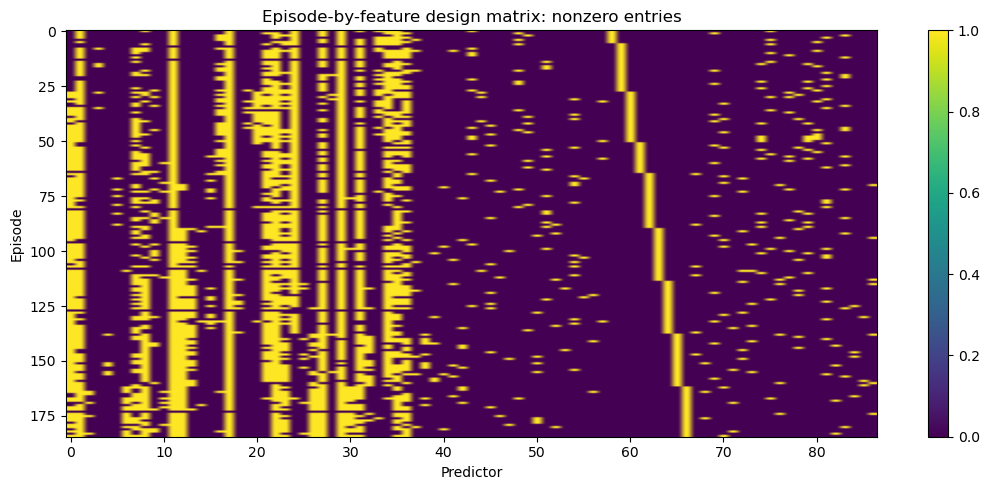

In [9]:
matrix_sparsity = (X.to_numpy() == 0).mean()
print(f"Fraction of zero entries in X: {matrix_sparsity:.3f}")

presence = (X.to_numpy() != 0).astype(int)

plt.figure(figsize=(11, 5))

plt.imshow(presence, aspect="auto")
plt.colorbar()
plt.xlabel("Predictor")
plt.ylabel("Episode")
plt.title("Episode-by-feature design matrix: nonzero entries")
plt.tight_layout()
plt.show()


Fraction of zero entries in X: 0.811


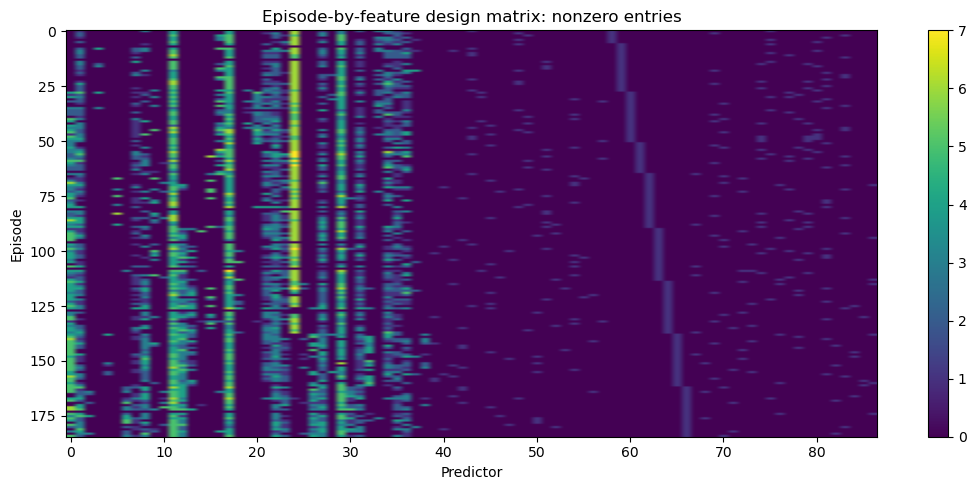

In [10]:
matrix_sparsity = (X.to_numpy() == 0).mean()
print(f"Fraction of zero entries in X: {matrix_sparsity:.3f}")

presence = (X.to_numpy()).astype(int)

plt.figure(figsize=(11, 5))

plt.imshow(presence, aspect="auto")
plt.colorbar()
plt.xlabel("Predictor")
plt.ylabel("Episode")
plt.title("Episode-by-feature design matrix: nonzero entries")
plt.tight_layout()
plt.show()


## 10. Train/test split

The test set is held out **before** choosing any regularization parameter.

$
D_{\mathrm{train}}\cap D_{\mathrm{test}}=\varnothing.
$

All model selection happens using the training set only.


In [11]:
# Keep the test set untouched during model selection.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
)

print("Training episodes:", len(X_train))
print("Test episodes:", len(X_test))


Training episodes: 138
Test episodes: 47


## 11. Why standardization matters

Ridge and lasso penalize coefficient magnitudes. Predictors must therefore be placed on comparable scales.

We use

$
Z_{ij}
=
\frac{X_{ij}-\bar X_j}{s_j}.
$

Crucially, scaling is performed **inside each cross-validation training fold** using a scikit-learn `Pipeline`, avoiding information leakage.


## 12. OLS baseline

OLS solves

$
\hat\beta_{\mathrm{OLS}}
=
\arg\min_\beta
\|\mathbf y-X\beta\|_2^2.
$


In [12]:
ols = Pipeline([
    ("scale", StandardScaler()),
    ("model", LinearRegression()),
])

ols.fit(X_train, y_train)

def regression_metrics(model, Xtr, Xte, ytr, yte):
    pred_train = model.predict(Xtr)
    pred_test = model.predict(Xte)

    return {
        "train_RMSE": np.sqrt(mean_squared_error(ytr, pred_train)),
        "test_RMSE": np.sqrt(mean_squared_error(yte, pred_test)),
        "train_R2": r2_score(ytr, pred_train),
        "test_R2": r2_score(yte, pred_test),
    }

ols_metrics = regression_metrics(
    ols, X_train, X_test, y_train, y_test
)

pd.Series(ols_metrics)


train_RMSE    0.262282
test_RMSE     0.533478
train_R2      0.778942
test_R2      -0.330746
dtype: float64

## 13. Ridge and lasso

Ridge:

$
\hat\beta^{\mathrm{ridge}}_\lambda
=
\arg\min_\beta
\left\{
\|\mathbf y-X\beta\|_2^2
+
\lambda\|\beta\|_2^2
\right\}.
$

Lasso:

$
\hat\beta^{\mathrm{lasso}}_\lambda
=
\arg\min_\beta
\left\{
\|\mathbf y-X\beta\|_2^2
+
\lambda\|\beta\|_1
\right\}.
$

We choose \(\lambda\) by \(K\)-fold cross-validation **using only the training data**.


In [13]:
cv = KFold(
    n_splits=N_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

ridge_lambdas = np.logspace(-4, 4, 100)
lasso_lambdas = np.logspace(-4, 0, 100)

ridge_search = GridSearchCV(
    estimator=Pipeline([
        ("scale", StandardScaler()),
        ("model", Ridge()),
    ]),
    param_grid={"model__alpha": ridge_lambdas},
    scoring="neg_mean_squared_error",
    cv=cv,
    n_jobs=-1,
)

lasso_search = GridSearchCV(
    estimator=Pipeline([
        ("scale", StandardScaler()),
        ("model", Lasso(max_iter=100000)),
    ]),
    param_grid={"model__alpha": lasso_lambdas},
    scoring="neg_mean_squared_error",
    cv=cv,
    n_jobs=-1,
)

ridge_search.fit(X_train, y_train)
lasso_search.fit(X_train, y_train)

lambda_ridge = ridge_search.best_params_["model__alpha"]
lambda_lasso = lasso_search.best_params_["model__alpha"]

print(f"Selected ridge lambda = {lambda_ridge:.6g}")
print(f"Selected lasso lambda = {lambda_lasso:.6g}")


Selected ridge lambda = 291.505
Selected lasso lambda = 0.0811131


## 14. Cross-validation curves


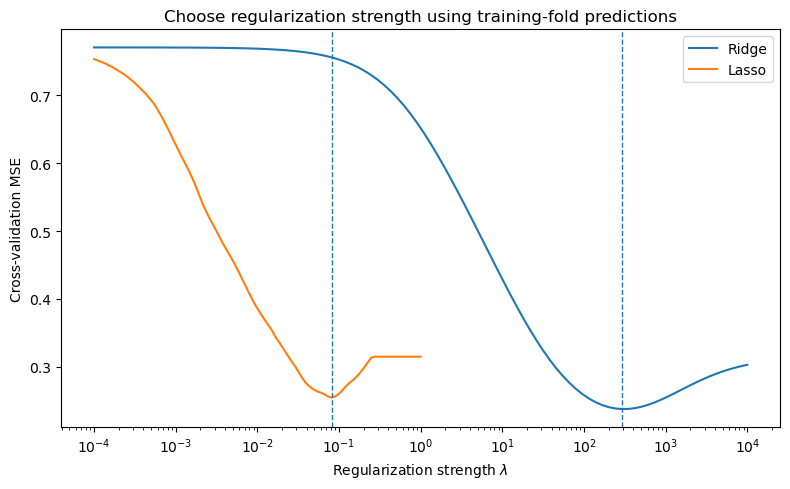

In [14]:
ridge_cv = pd.DataFrame(ridge_search.cv_results_)
lasso_cv = pd.DataFrame(lasso_search.cv_results_)

plt.figure(figsize=(8, 5))

plt.plot(
    ridge_cv["param_model__alpha"].astype(float),
    -ridge_cv["mean_test_score"],
    label="Ridge",
)
plt.plot(
    lasso_cv["param_model__alpha"].astype(float),
    -lasso_cv["mean_test_score"],
    label="Lasso",
)

plt.axvline(lambda_ridge, linestyle="--", linewidth=1)
plt.axvline(lambda_lasso, linestyle="--", linewidth=1)

plt.xscale("log")
plt.xlabel(r"Regularization strength $\lambda$")
plt.ylabel("Cross-validation MSE")
plt.title("Choose regularization strength using training-fold predictions")
plt.legend()
plt.tight_layout()
plt.show()


## 15. Final OLS, ridge, and lasso comparison

After choosing \(\lambda\), each regularized model is refit on the full training set and evaluated once on the untouched test set.


In [15]:
ridge = ridge_search.best_estimator_
lasso = lasso_search.best_estimator_

ridge_metrics = regression_metrics(
    ridge, X_train, X_test, y_train, y_test
)
lasso_metrics = regression_metrics(
    lasso, X_train, X_test, y_train, y_test
)

comparison = pd.DataFrame(
    [ols_metrics, ridge_metrics, lasso_metrics],
    index=["OLS", "Ridge", "Lasso"],
)

display(comparison.round(3))


,train_RMSE,test_RMSE,train_R2,test_R2
OLS,0.262,0.533,0.779,-0.331
Ridge,0.397,0.375,0.493,0.344
Lasso,0.461,0.386,0.318,0.304


## 16. Shrinkage versus sparsity

Retrieve coefficients on the standardized predictor scale.

Ridge generally makes coefficients smaller:

$
\beta_j\rightarrow 0.
$

Lasso can make them **exactly zero**:

$
\beta_j=0.
$


In [16]:
feature_names = X.columns.to_numpy()

coef_ols = ols.named_steps["model"].coef_
coef_ridge = ridge.named_steps["model"].coef_
coef_lasso = lasso.named_steps["model"].coef_

coef_table = pd.DataFrame({
    "feature": feature_names,
    "OLS": coef_ols,
    "Ridge": coef_ridge,
    "Lasso": coef_lasso,
})

print("Total predictors:", len(feature_names))
print("OLS nonzero:", np.count_nonzero(np.abs(coef_ols) > 1e-10))
print("Ridge nonzero:", np.count_nonzero(np.abs(coef_ridge) > 1e-10))
print("Lasso nonzero:", np.count_nonzero(np.abs(coef_lasso) > 1e-10))

display(
    coef_table.loc[np.abs(coef_table["Lasso"]) > 1e-10]
    .sort_values("Lasso")
)


Total predictors: 87
OLS nonzero: 87
Ridge nonzero: 87
Lasso nonzero: 10


,feature,OLS,Ridge,Lasso
65,season: 8,-0.074623,-0.033912,-0.067337
26,character: Nellie,-0.229618,-0.039528,-0.065889
12,character: Erin,0.041796,-0.024111,-0.028042
72,writer: Charlie Grandy,-0.057938,-0.025766,-0.017975
37,character: Todd Packer,-0.082087,-0.024242,-0.005192
51,director: Paul Feig,0.017939,0.027233,0.023996
75,writer: Greg Daniels,0.165762,0.034957,0.025735
1,character: Angela,0.072602,0.021994,0.027201
31,character: Phyllis,0.008241,0.024939,0.039058
24,character: Michael,-0.108737,0.026774,0.062695


## 17. Features retained by lasso

Because the predictors were standardized before fitting, the coefficients are displayed on a comparable standardized scale.

Interpretation:

- \(\hat\beta_j>0\): associated with a higher rating conditional on the other predictors;
- \(\hat\beta_j<0\): associated with a lower rating conditional on the other predictors;
- \(\hat\beta_j=0\): excluded by the selected lasso fit.

These are **not causal effects**.


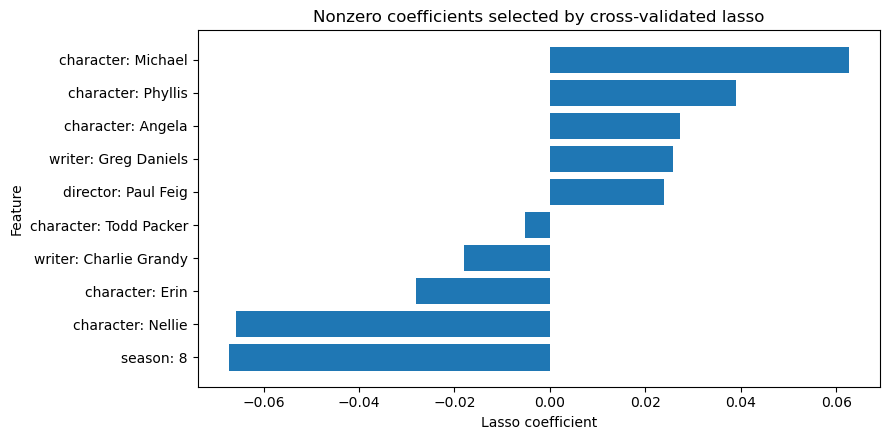

In [17]:
selected = (
    coef_table.loc[np.abs(coef_table["Lasso"]) > 1e-10]
    .sort_values("Lasso")
    .copy()
)

plt.figure(figsize=(9, max(4.5, 0.28 * len(selected))))
plt.barh(selected["feature"], selected["Lasso"])
plt.xlabel("Lasso coefficient")
plt.ylabel("Feature")
plt.title("Nonzero coefficients selected by cross-validated lasso")
plt.tight_layout()
plt.show()


## 18. Lasso coefficient path

To isolate the effect of \(\lambda\), standardize the training matrix once and fit lasso over a dense grid.

As \(\lambda\) increases,

$
\#\{j:\hat\beta_j(\lambda)\neq 0\}
$

typically decreases.


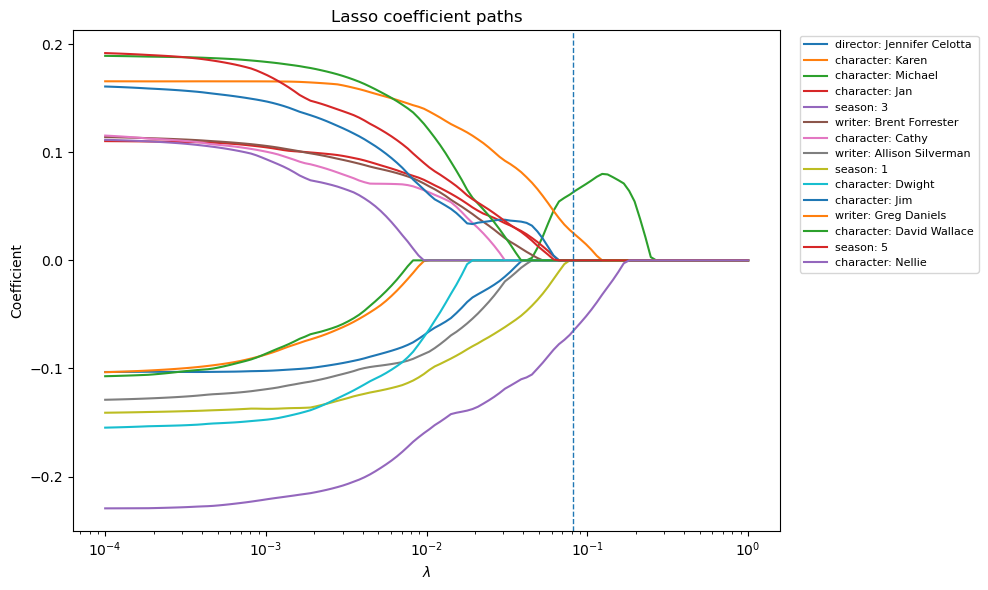

In [18]:
scaler_path = StandardScaler()
X_train_std = scaler_path.fit_transform(X_train)

path_lambdas = np.logspace(-4, 0, 120)
path_coefs = []

for lam in path_lambdas:
    model = Lasso(alpha=lam, max_iter=100000)
    model.fit(X_train_std, y_train)
    path_coefs.append(model.coef_)

path_coefs = np.asarray(path_coefs)

# Show the 15 predictors with the largest coefficient somewhere on the path.
importance = np.max(np.abs(path_coefs), axis=0)
top_idx = np.argsort(importance)[-15:]

plt.figure(figsize=(10, 6))

for j in top_idx:
    plt.plot(
        path_lambdas,
        path_coefs[:, j],
        label=feature_names[j],
    )

plt.axvline(lambda_lasso, linestyle="--", linewidth=1)
plt.xscale("log")
plt.xlabel(r"$\lambda$")
plt.ylabel("Coefficient")
plt.title("Lasso coefficient paths")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()


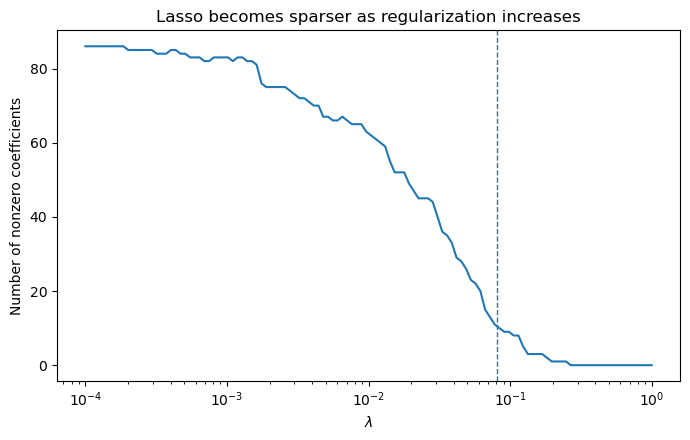

In [19]:
nonzero_path = np.sum(np.abs(path_coefs) > 1e-10, axis=1)

plt.figure(figsize=(7, 4.5))
plt.plot(path_lambdas, nonzero_path)
plt.axvline(lambda_lasso, linestyle="--", linewidth=1)
plt.xscale("log")
plt.xlabel(r"$\lambda$")
plt.ylabel("Number of nonzero coefficients")
plt.title("Lasso becomes sparser as regularization increases")
plt.tight_layout()
plt.show()


## 19. Compare OLS, ridge, and lasso coefficients

This plot shows the largest coefficients under ridge or lasso.

A useful discussion point is what happens to **correlated predictors**:

- ridge can distribute weight among correlated features;
- lasso can retain one while setting another to zero;
- the selected feature should therefore not automatically be interpreted as uniquely important.


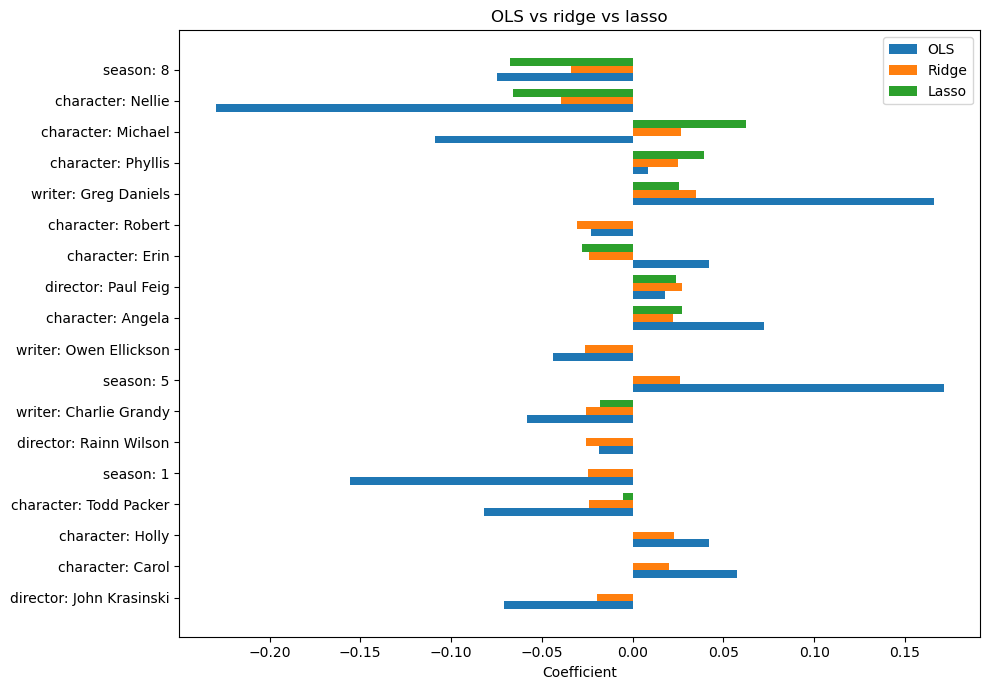

In [20]:
coef_compare = coef_table.copy()
coef_compare["importance"] = np.maximum(
    np.abs(coef_compare["Ridge"]),
    np.abs(coef_compare["Lasso"]),
)

top = (
    coef_compare.nlargest(18, "importance")
    .sort_values("importance")
)

pos = np.arange(len(top))
width = 0.25

plt.figure(figsize=(10, 7))
plt.barh(pos - width, top["OLS"], height=width, label="OLS")
plt.barh(pos, top["Ridge"], height=width, label="Ridge")
plt.barh(pos + width, top["Lasso"], height=width, label="Lasso")
plt.yticks(pos, top["feature"])
plt.xlabel("Coefficient")
plt.title("OLS vs ridge vs lasso")
plt.legend()
plt.tight_layout()
plt.show()


## 20. Optional Bayesian connection

Under Gaussian observation noise,
$
p(\mathbf y\mid X,\beta)
\propto
\exp\left[
-\frac{1}{2\sigma^2}
\|\mathbf y-X\beta\|_2^2
\right].
$

A Gaussian prior

$
\beta_j\sim\mathcal N(0,\tau^2)
$

gives

$
-\log p(\beta)
\propto
\sum_j\beta_j^2,
$

and therefore a ridge MAP objective.

A Laplace prior

$
p(\beta_j)\propto e^{-|\beta_j|/b}
$

gives

\[
-\log p(\beta)
\propto
\sum_j|\beta_j|,
\]

and therefore a lasso MAP objective.


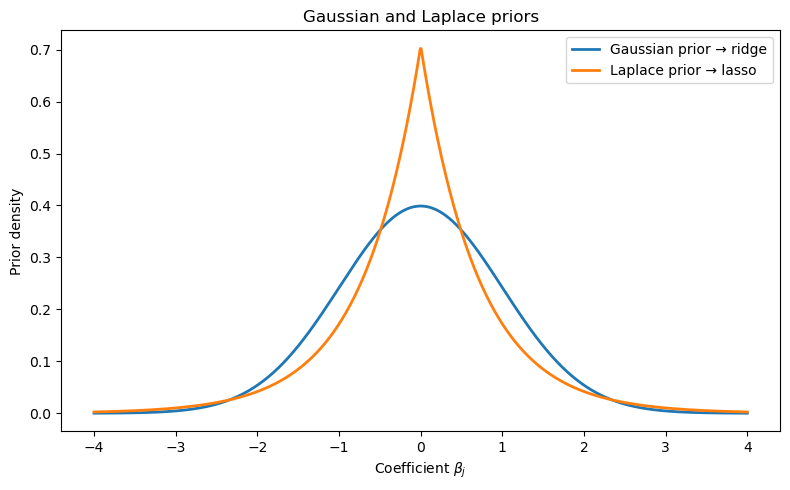

In [21]:
beta_grid = np.linspace(-4, 4, 800)

# Equal-variance comparison:
# Var[N(0,1)] = 1, Var[Laplace(0,b)] = 2b^2 = 1
sigma_prior = 1.0
b_prior = 1 / np.sqrt(2)

gaussian = (
    1 / np.sqrt(2 * np.pi * sigma_prior**2)
    * np.exp(-(beta_grid**2) / (2 * sigma_prior**2))
)

laplace = (
    1 / (2 * b_prior)
    * np.exp(-np.abs(beta_grid) / b_prior)
)

plt.figure(figsize=(8, 5))
plt.plot(beta_grid, gaussian, linewidth=2, label="Gaussian prior → ridge")
plt.plot(beta_grid, laplace, linewidth=2, label="Laplace prior → lasso")
plt.xlabel(r"Coefficient $\beta_j$")
plt.ylabel("Prior density")
plt.title("Gaussian and Laplace priors")
plt.legend()
plt.tight_layout()
plt.show()


# Takeaways

\[
\boxed{
\begin{array}{lll}
\text{OLS}
&:&
\text{no coefficient penalty},
\\[4pt]
\text{Ridge}
&:&
L_2\text{ penalty } \rightarrow \text{shrinkage},
\\[4pt]
\text{Lasso}
&:&
L_1\text{ penalty } \rightarrow \text{shrinkage + sparsity}.
\end{array}
}
\]

For this case study:

1. transcript information naturally produces many sparse predictors;
2. \(\lambda\) is selected using cross-validation on the training data;
3. the test set is used only after model selection;
4. lasso can reduce a large candidate feature set to a sparse fitted model;
5. nonzero coefficients describe **conditional associations**, not causal effects.

### Classroom experiment

Change the three thresholds in the setup cell and rerun:

```python
MIN_CHARACTER_LINES = 50
MIN_CHARACTER_EPISODES = 5
MIN_CREATOR_EPISODES = 3
```

Lower thresholds create a larger and sparser candidate feature set. Compare what happens to:

- OLS test error;
- selected ridge/lasso \(\lambda\);
- coefficient magnitudes;
- number of nonzero lasso coefficients.
